# TimeGym · Quick Start

**Does the pipeline behave sensibly across different kinds of series?** Fit fresh cases, then inspect them together.

Install once from the repository root: `python -m pip install -e '.[notebooks]'`.

In [1]:
import matplotlib.pyplot as plt
from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler
from timegym import Pipeline, Scenario

%matplotlib inline


## Several tests, side by side

Each row fixes the process; each column changes its random seed. Five families give six configurations because we show random walks both **without drift** and **with drift**. Every case has 300 history points and 100 genuinely future points.

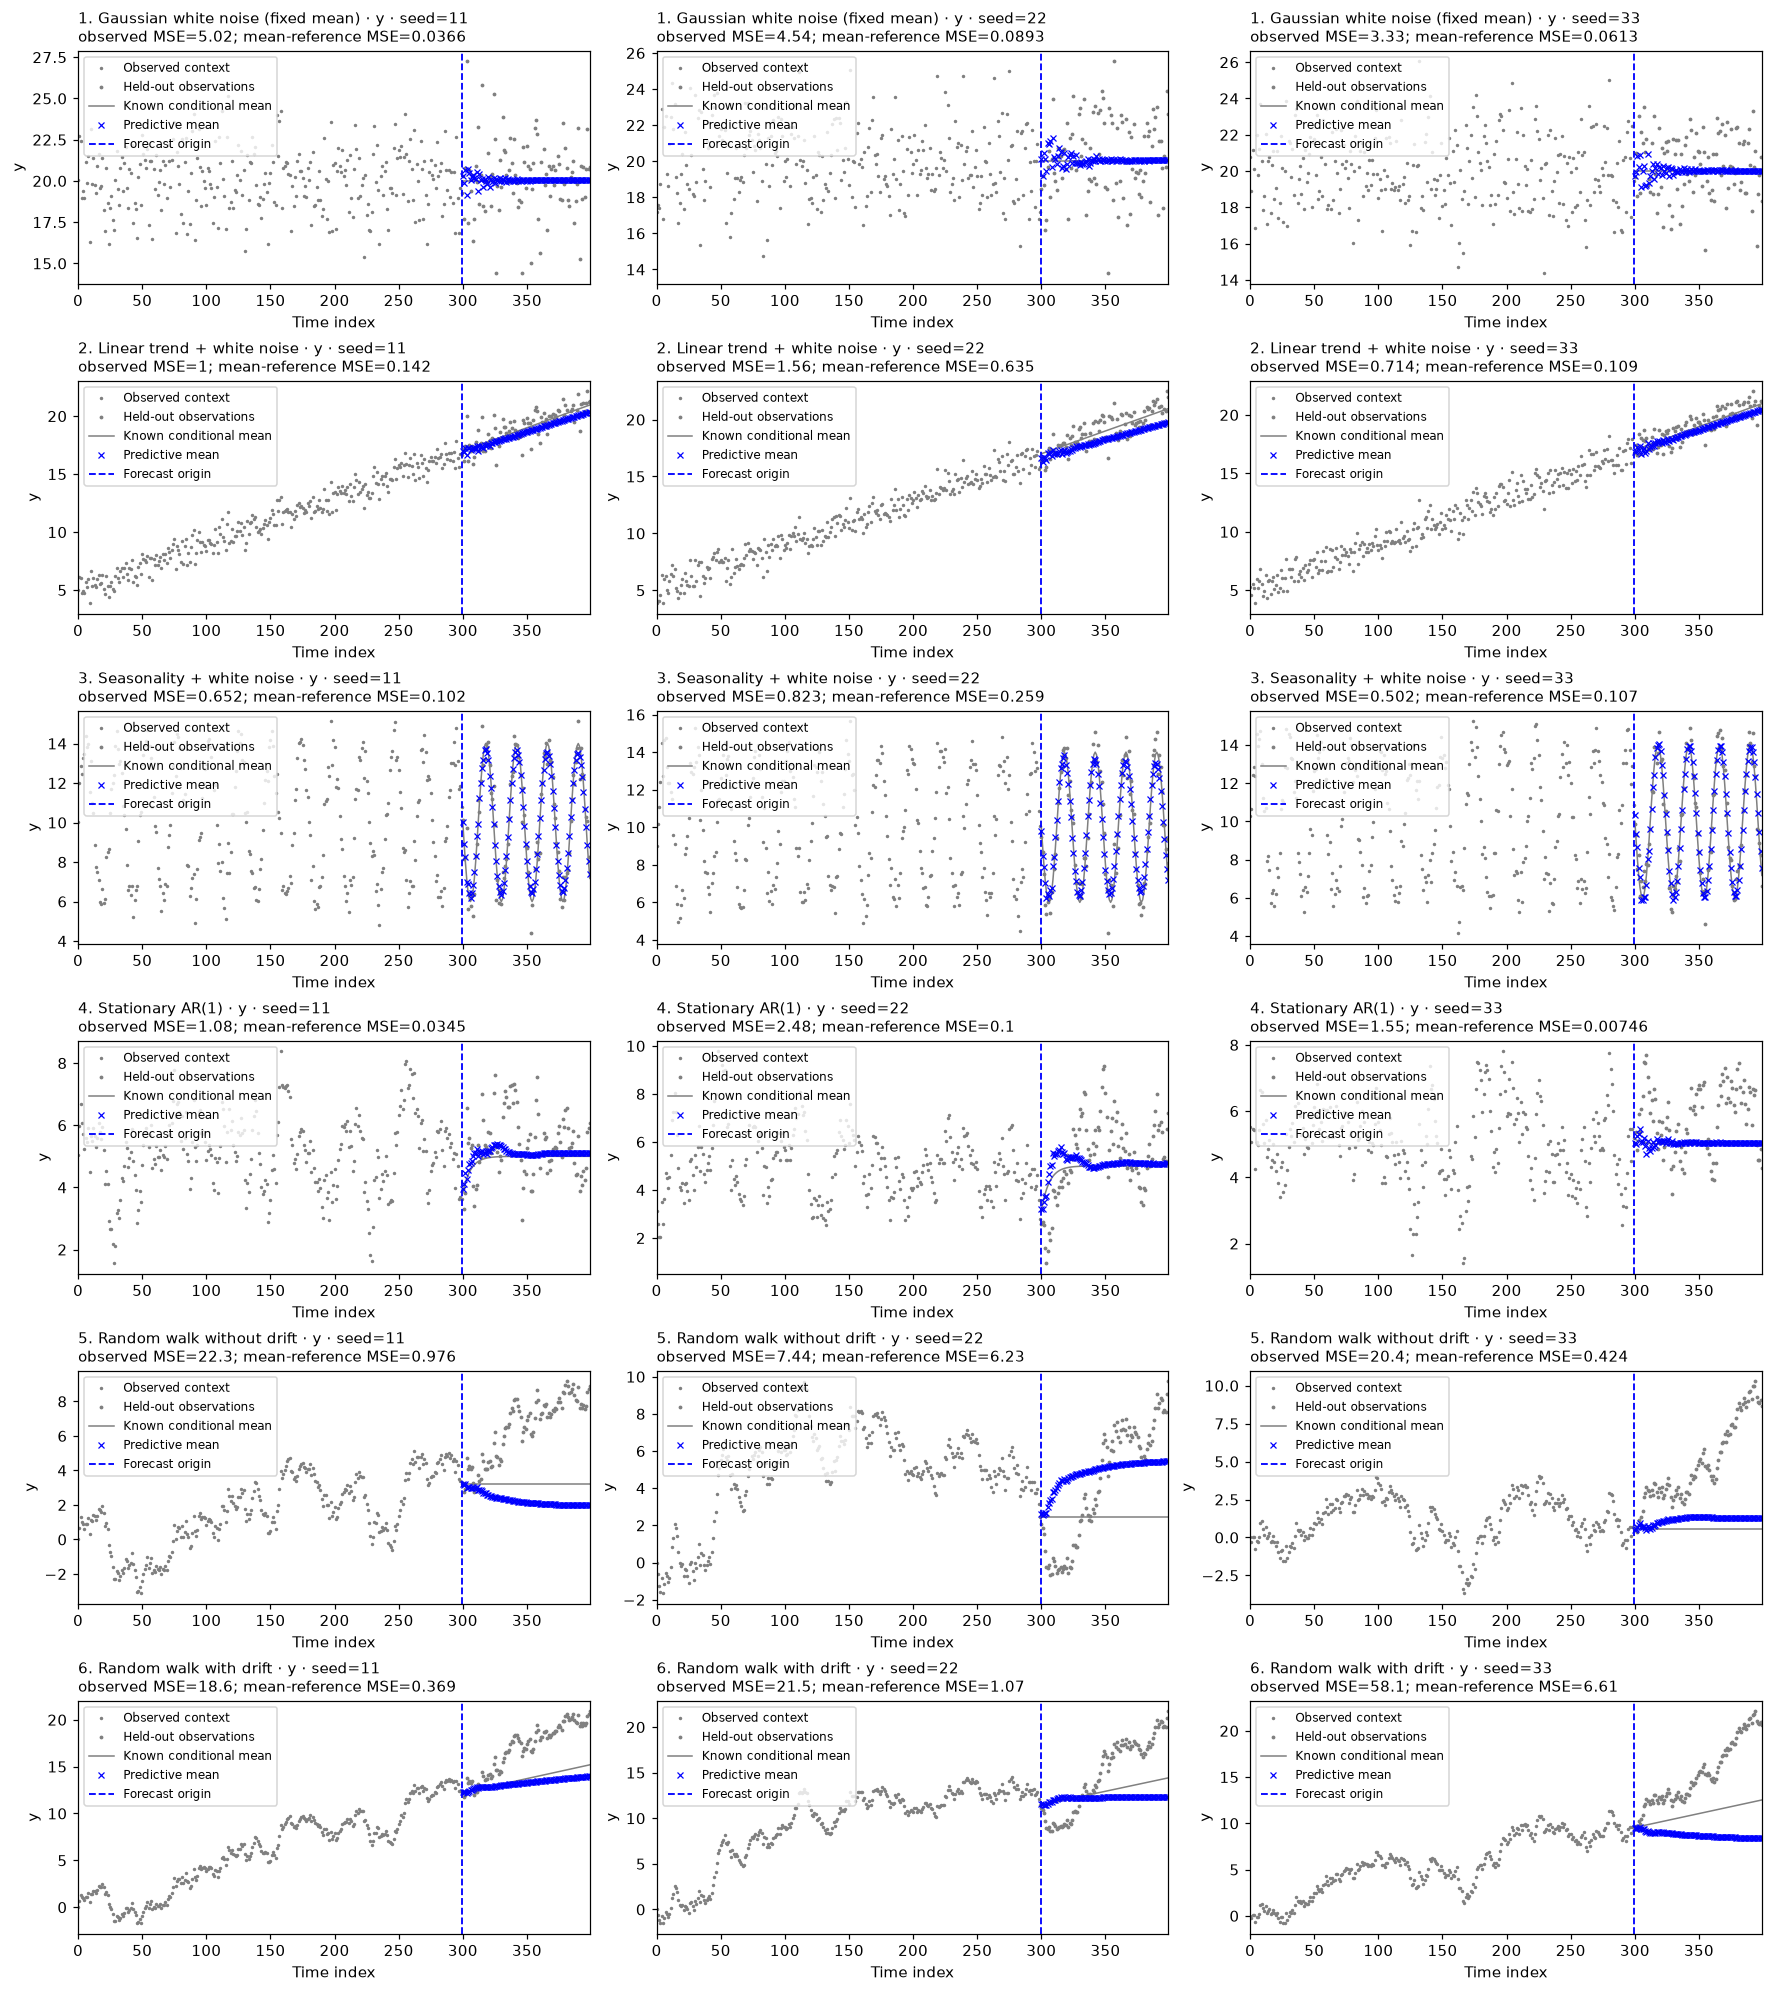

In [2]:
matrix_specs = [
    {
        "kind": "white_noise",
        "context_length": 300,
        "horizon": 100,
        "parameters": {
            "mean": 20.0,
            "sigma": 2.0
        }
    },
    {
        "kind": "trend",
        "context_length": 300,
        "horizon": 100,
        "parameters": {
            "intercept": 5.0,
            "slope": 0.04,
            "sigma": 0.8
        }
    },
    {
        "kind": "seasonal",
        "context_length": 300,
        "horizon": 100,
        "parameters": {
            "mean": 10.0,
            "amplitude": 4.0,
            "period": 24.0,
            "sigma": 0.7
        }
    },
    {
        "kind": "ar1",
        "context_length": 300,
        "horizon": 100,
        "parameters": {
            "mean": 5.0,
            "phi": 0.85,
            "sigma": 0.7
        }
    },
    {
        "kind": "random_walk",
        "context_length": 300,
        "horizon": 100,
        "parameters": {
            "drift": 0.0,
            "sigma": 0.5
        }
    },
    {
        "kind": "random_walk",
        "context_length": 300,
        "horizon": 100,
        "parameters": {
            "drift": 0.03,
            "sigma": 0.5
        }
    }
]
matrix_seeds = [11, 22, 33]
matrix_model = {"window_length": 24, "ridge_alpha": 1.0}
scenarios = [Scenario(**spec) for spec in matrix_specs]
pipeline = Pipeline(window_length=matrix_model["window_length"]).add(StandardScaler()).add(Ridge(alpha=matrix_model["ridge_alpha"]))
run = pipeline.run(scenarios, seeds=matrix_seeds)
run.plot_forecasts(figsize=(16, 18));
plt.show()

Gray **dots** are observations; blue **crosses** are predicted means. The dashed line marks the forecast origin. The thin gray future curve is the known conditional mean.

**White noise is not a random walk.** Fixed-mean white noise, linear trend plus white noise, and fixed seasonality plus white noise add fresh, temporary shocks around their mean. A random walk **accumulates** shocks. The last two rows share exactly the same shocks within each seed; adding drift `0.03` changes the level at time `t` by `0.03*t`. The zero-drift walk can still wander upward or downward by chance. With known parameters, its forecast variance grows as `h*sigma**2`; these three fresh-noise processes keep variance `sigma**2`. Each panel has its own value scale.

A fixed seasonal cycle repeats; it is not a drift term or a changing mechanism. Changes to its amplitude, period, or phase belong in a separate controlled-change case.

## Is that behavior repeatable?

Use 24 independently generated cases per configuration, paired across configurations by seed. Each histogram measures distance from the correct conditional mean; it does not count horizons as independent replications.

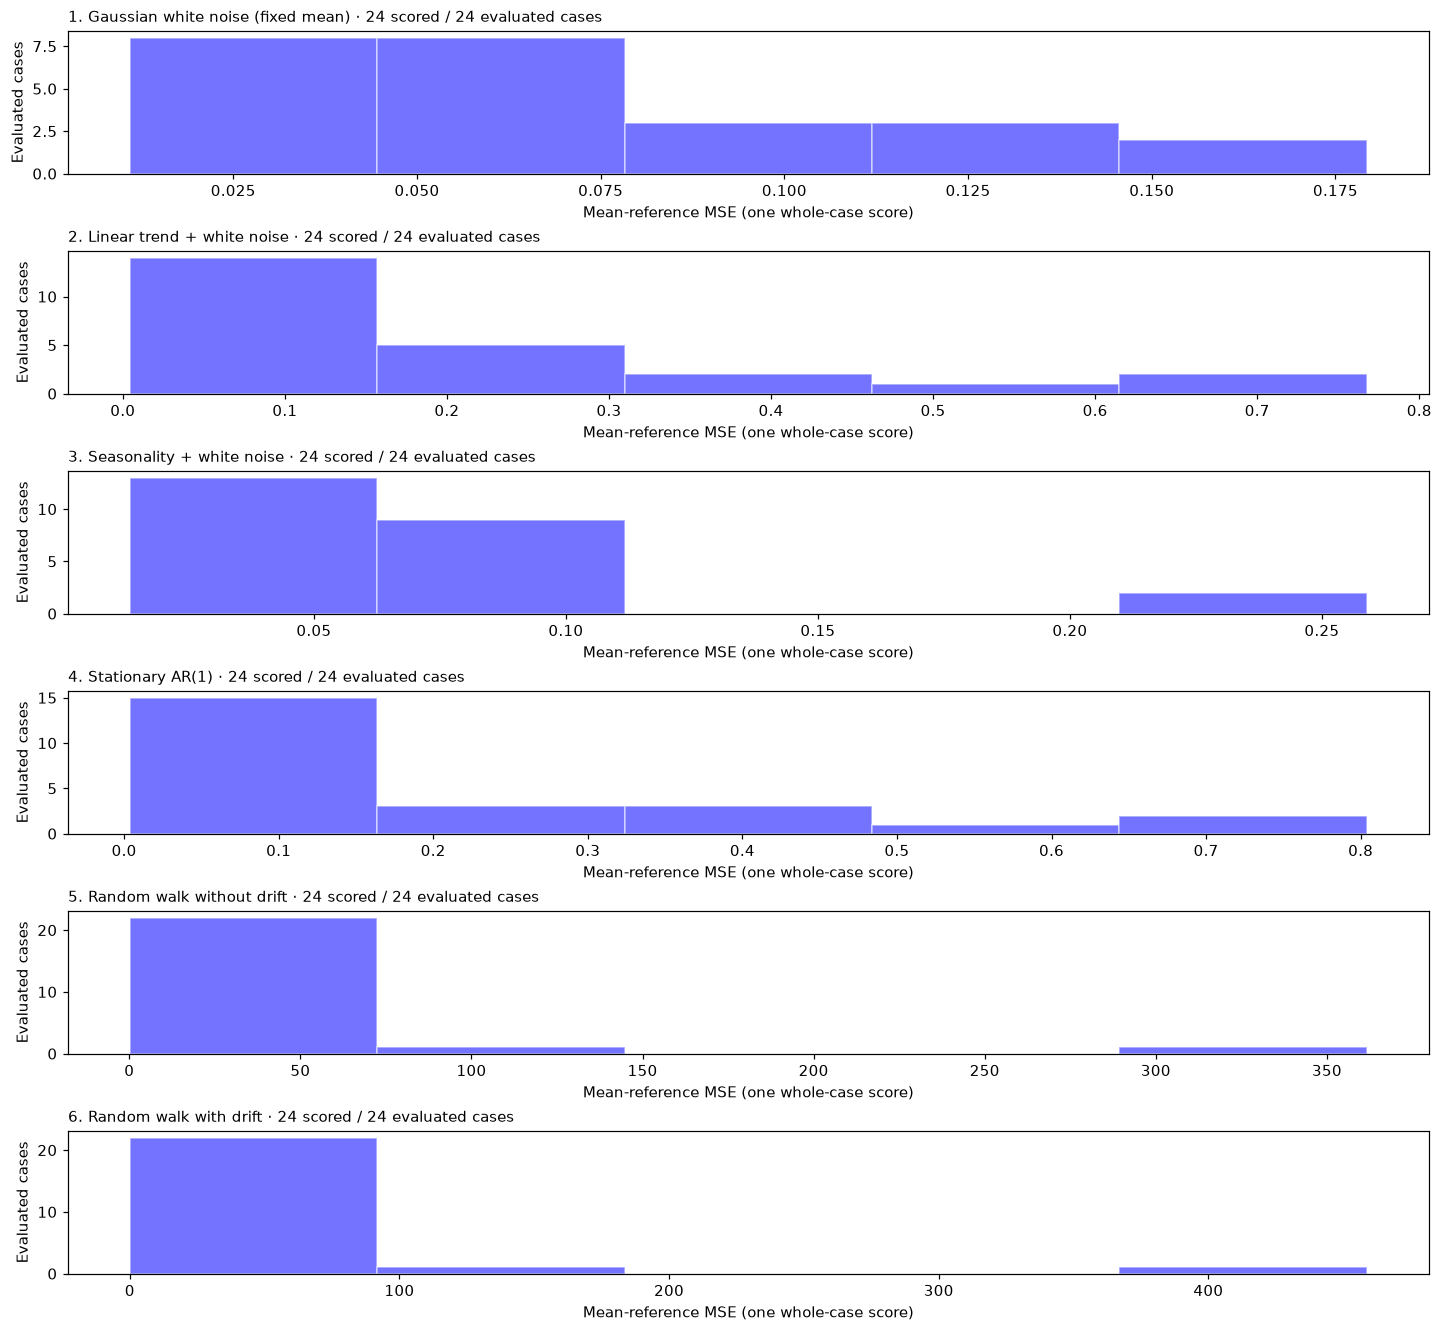

In [3]:
replications = pipeline.run(scenarios, seeds=range(24))
replications.plot_errors(metric='mean_reference_mse', figsize=(13, 12));
plt.show()

Plotting reuses retained predictions. The structured diagnostics remain available as `run.report`; predictions and observations are in `run.cases`.

In [4]:
assert len(run.cases) == len(scenarios) * 3
assert len(replications.cases) == len(scenarios) * 24
run.report.summary

{'cases': 18,
 'diagnostics': 72,
 'status_counts': {'PASS': 18,
  'FAIL': 0,
  'INCONCLUSIVE': 18,
  'UNSUPPORTED': 36,
  'ERROR': 0},
 'failed_cases': 0}

Change the model or one parameter and rerun the same seeds.

[Build the library](07_pipeline.ipynb) · [Univariate uncertainty](20_univariate_uncertainty.ipynb) · [Multiple targets](21_multivariate_forecasting.ipynb) · [Joint uncertainty](22_multivariate_uncertainty.ipynb) · [Composed and financial stresses](26_composed_and_financial_stresses.ipynb) · [All notebooks](README.md)